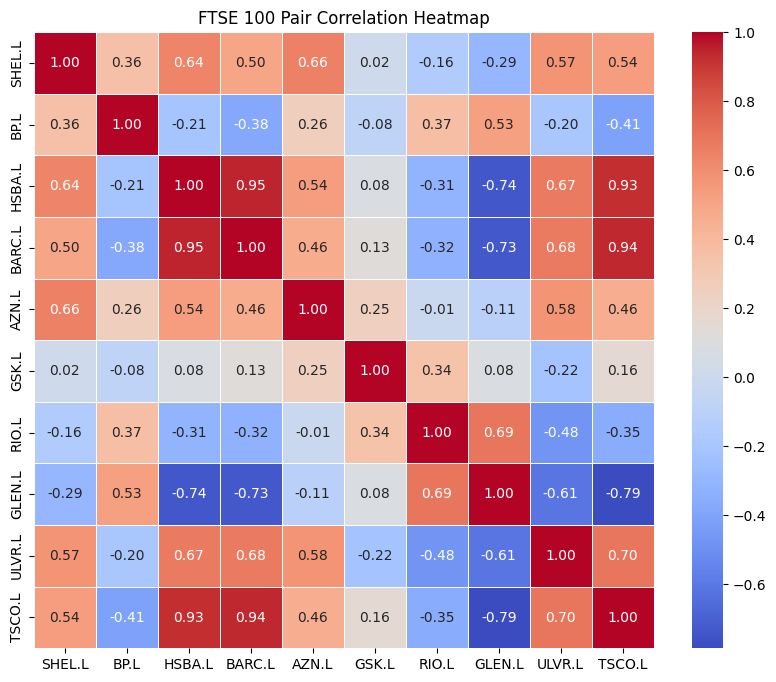


--- Top 10 Potential Pairs ---
BARC.L  HSBA.L    0.949133
HSBA.L  BARC.L    0.949133
BARC.L  TSCO.L    0.937782
TSCO.L  BARC.L    0.937782
        HSBA.L    0.926608
HSBA.L  TSCO.L    0.926608
ULVR.L  TSCO.L    0.698376
TSCO.L  ULVR.L    0.698376
RIO.L   GLEN.L    0.694330
GLEN.L  RIO.L     0.694330
dtype: float64


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

# 1. Load the data
# We tell pandas the first column is our 'Date' index
data_path = os.path.join('..', 'data', 'ftse_prices.csv')
df = pd.read_csv(data_path, index_col=0, parse_dates=True)

# 2. Calculate the Correlation Matrix
# This tells us how much two stocks move in the same direction (-1 to 1)
corr_matrix = df.corr()

# 3. Create the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('FTSE 100 Pair Correlation Heatmap')
plt.show()

# 4. Find the 'Top Hunters'
# We unstack the matrix and sort to find the highest correlations (excluding 1.0)
corr_pairs = corr_matrix.unstack().sort_values(ascending=False)
top_pairs = corr_pairs[corr_pairs < 1.0].head(10)

print("\n--- Top 10 Potential Pairs ---")
print(top_pairs)

--- Cointegration Results for HSBA vs BARC ---
P-Value: 0.0310
Hedge Ratio (Beta): 1.9121

✅ SUCCESS: The pair is cointegrated!


/var/folders/dk/5qx6qk6s2pq27mm6zdwd1xym0000gn/T/ipykernel_7651/3151637703.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[1]


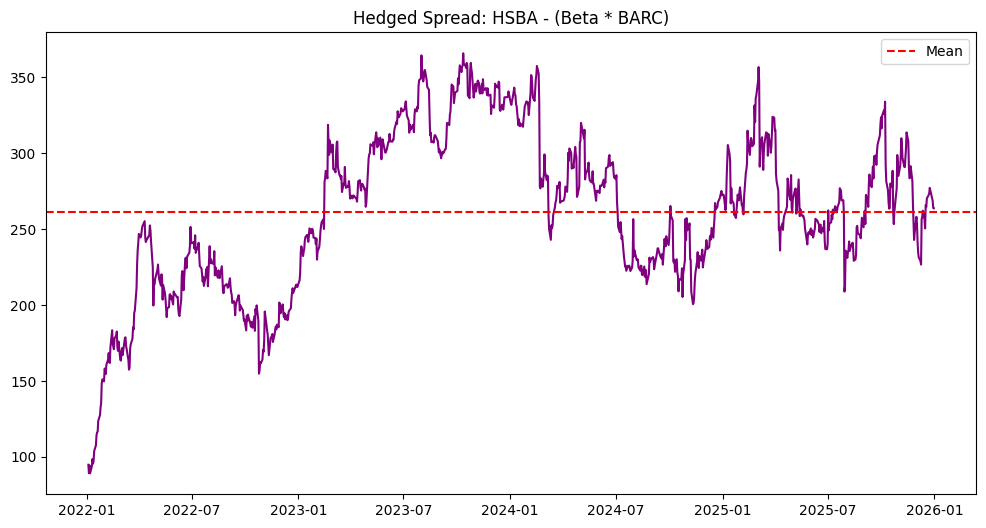

In [4]:
from statsmodels.tsa.stattools import coint
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Select the pair and drop any missing values specifically for these two
# This ensures both series have exactly the same length and no NaNs
pair_data = df[['HSBA.L', 'BARC.L']].dropna()

stock_y = pair_data['HSBA.L']
stock_x = pair_data['BARC.L']

# 2. Calculate Cointegration p-value
# Now that data is clean, coint() will work
score, pvalue, _ = coint(stock_y, stock_x)

# 3. Calculate the Hedge Ratio (Beta) using Linear Regression
X = sm.add_constant(stock_x) 
model = sm.OLS(stock_y, X).fit()
beta = model.params[1]

# 4. Generate and Plot the Spread
spread = stock_y - (beta * stock_x)

print(f"--- Cointegration Results for HSBA vs BARC ---")
print(f"P-Value: {pvalue:.4f}")
print(f"Hedge Ratio (Beta): {beta:.4f}")

if pvalue < 0.05:
    print("\n✅ SUCCESS: The pair is cointegrated!")
else:
    print("\n❌ FAIL: High p-value. The relationship isn't stable enough for this strategy.")

plt.figure(figsize=(12, 6))
plt.plot(spread, color='purple')
plt.axhline(spread.mean(), color='red', linestyle='--', label='Mean')
plt.title('Hedged Spread: HSBA - (Beta * BARC)')
plt.legend()
plt.show()

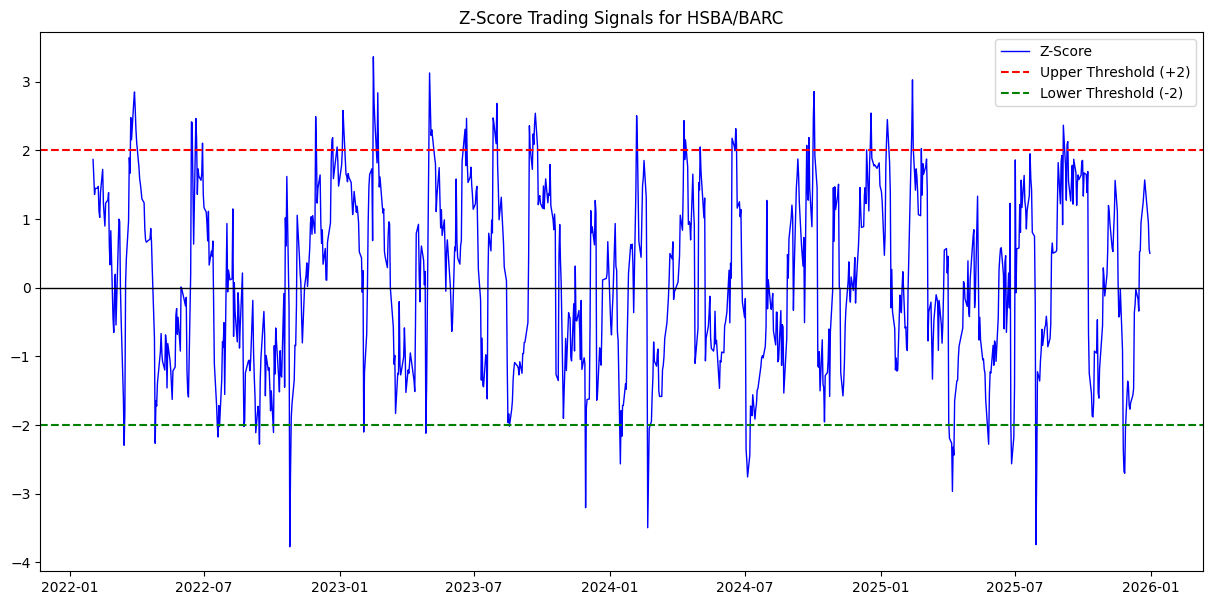

Total potential 'Sell' signals: 65
Total potential 'Buy' signals: 39


In [5]:
# 1. Calculate the Rolling Z-Score
# We use a 21-day window (roughly 1 trading month)
window = 21
spread_mean = spread.rolling(window=window).mean()
spread_std = spread.rolling(window=window).std()
z_score = (spread - spread_mean) / spread_std

# 2. Visualize the Z-Score
plt.figure(figsize=(15, 7))
plt.plot(z_score, label='Z-Score', color='blue', lw=1)

# 3. Add Thresholds
plt.axhline(0, color='black', lw=1)
plt.axhline(2.0, color='red', linestyle='--', label='Upper Threshold (+2)')
plt.axhline(-2.0, color='green', linestyle='--', label='Lower Threshold (-2)')

plt.title('Z-Score Trading Signals for HSBA/BARC')
plt.legend()
plt.show()

# 4. Count the potential trades
trades_high = z_score[z_score > 2].count()
trades_low = z_score[z_score < -2].count()

print(f"Total potential 'Sell' signals: {trades_high}")
print(f"Total potential 'Buy' signals: {trades_low}")